# Analyse exploratoire : churn des clients Telco

Données : *Telco Customer Churn* (IBM, via Kaggle), 7 043 clients et 21 colonnes.
Objectif : comprendre quels clients partent, avant de construire un modèle.

**Plan**
1. Chargement et contrôle qualité
2. Nettoyage
3. Variable cible
4. Variables numériques
5. Variables catégorielles
6. Le churn selon les variables
7. Constats et décisions pour la modélisation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Chargement et contrôle qualité

In [ ]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [ ]:
print("Doublons            :", df.duplicated().sum())
print("customerID uniques  :", df["customerID"].nunique())
print("Valeurs manquantes  :", df.isnull().sum().sum())

Doublons            : 0
customerID uniques  : 7043
Valeurs manquantes  : 0


`TotalCharges` est lue comme du texte alors qu'elle devrait être numérique.
Je regarde d'abord pourquoi avant de la convertir.

## 2. Nettoyage

In [ ]:
# customerID est juste un identifiant, il n'apporte rien au modèle
df = df.drop(columns=["customerID"])

In [ ]:
# astype(float) échoue : certaines valeurs de TotalCharges sont un simple espace " "
vides = df["TotalCharges"].str.strip() == ""
print("Lignes vides :", vides.sum())
print("tenure de ces lignes :", df.loc[vides, "tenure"].unique())

Lignes vides : 11
tenure de ces lignes : [0]


Toutes les lignes vides ont `tenure = 0` : ce sont des clients arrivés ce mois-ci, rien n'a encore été facturé.
Je les remplace donc par 0 au lieu de les supprimer.

In [ ]:
df["TotalCharges"] = df["TotalCharges"].replace({" ": "0.0"}).astype(float)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

## 3. Variable cible

In [ ]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True).round(3))


churn = (df["Churn"] == "Yes").astype(int)


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


**Insights**
1. `customerID` supprimé : inutile pour la modélisation.
2. Aucune valeur manquante dans le jeu de données.
3. `TotalCharges` était en texte, et la valeur 0 était représentée par `" "` (clients avec `tenure = 0`).
4. Classes déséquilibrées : 5 174 « No » contre 1 869 « Yes » (environ 73 % / 27 %).

## 4. Variables numériques

In [ ]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
df[num_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


### Distributions

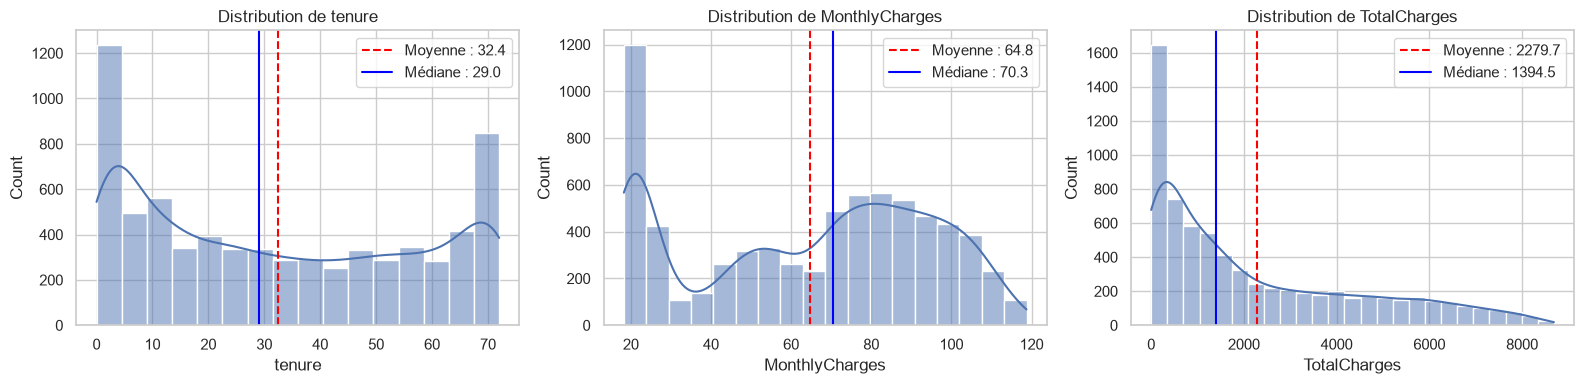

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label=f"Moyenne : {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="blue", label=f"Médiane : {df[col].median():.1f}")
    ax.set_title(f"Distribution de {col}")
    ax.legend()
plt.tight_layout()
plt.show()

**Ce que je vois :** 

-*tenure : Distribution en « U » (bimodale) avec beaucoup de nouveaux clients (< 5 mois) et beaucoup de très anciens (> 70 mois). La moyenne (32.4) et la médiane (29.0) sont assez proches.*

-*MonthlyCharges : Distribution asymétrique à gauche avec un gros pic à 20 $ (petits forfaits) et une concentration entre 70 $ et 90 $. La médiane (70.3) est plus haute que la moyenne (64.8).* 

-*TotalCharges : Distribution très asymétrique à droite. La majorité paye peu, mais quelques clients de longue date tirent la moyenne (2279.7) loin au-dessus de la médiane (1394.5).*

### Boîtes à moustaches selon le churn

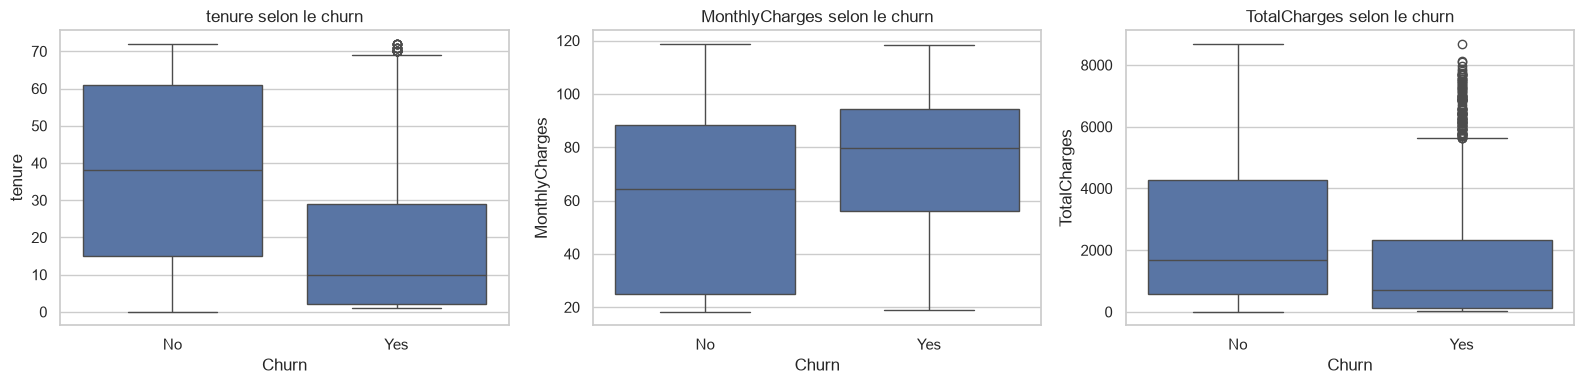

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df["Churn"], y=df[col], ax=ax)
    ax.set_title(f"{col} selon le churn")
plt.tight_layout()
plt.show()

**Ce que je vois :** 

                    *tenure : les clients qui partent (Yes) ont une ancienneté bien plus faible (médiane autour de 10 mois contre près de 38 mois pour ceux qui restent). On note quelques rares valeurs aberrantes tout en haut.*
                    *MonthlyCharges : les clients qui résilient payent nettement plus cher par mois (médiane vers 80 $ contre environ 64 $ pour les fidèles). Aucun outlier visible ici.*
                    *TotalCharges : La médiane de ceux qui partent est plus basse (car ils sont restés moins longtemps), mais il y a beaucoup de valeurs aberrantes (outliers) au-delà de 6 000 $ pour les clients partis.*

### Corrélations

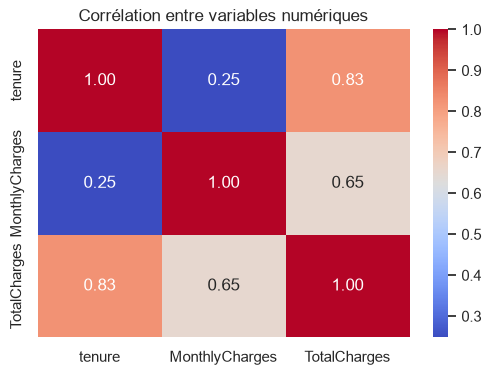

In [ ]:
plt.figure(figsize=(6, 4))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Corrélation entre variables numériques")
plt.show()

**Ce que je vois :** 

                    *Variables corrélées : tenure et TotalCharges présentent une très forte corrélation positive ($r = 0.83$), suivie de MonthlyCharges et TotalCharges ($r = 0.65$).*

**Pourquoi c'est logique :**

                    *les factures totales représentent le cumul dans le temps (TotalCharges = tenure * MonthlyCharges). Plus un client reste longtemps ou plus son forfait mensuel est cher, plus le total payé augmente naturellement.*

## 5. Variables catégorielles

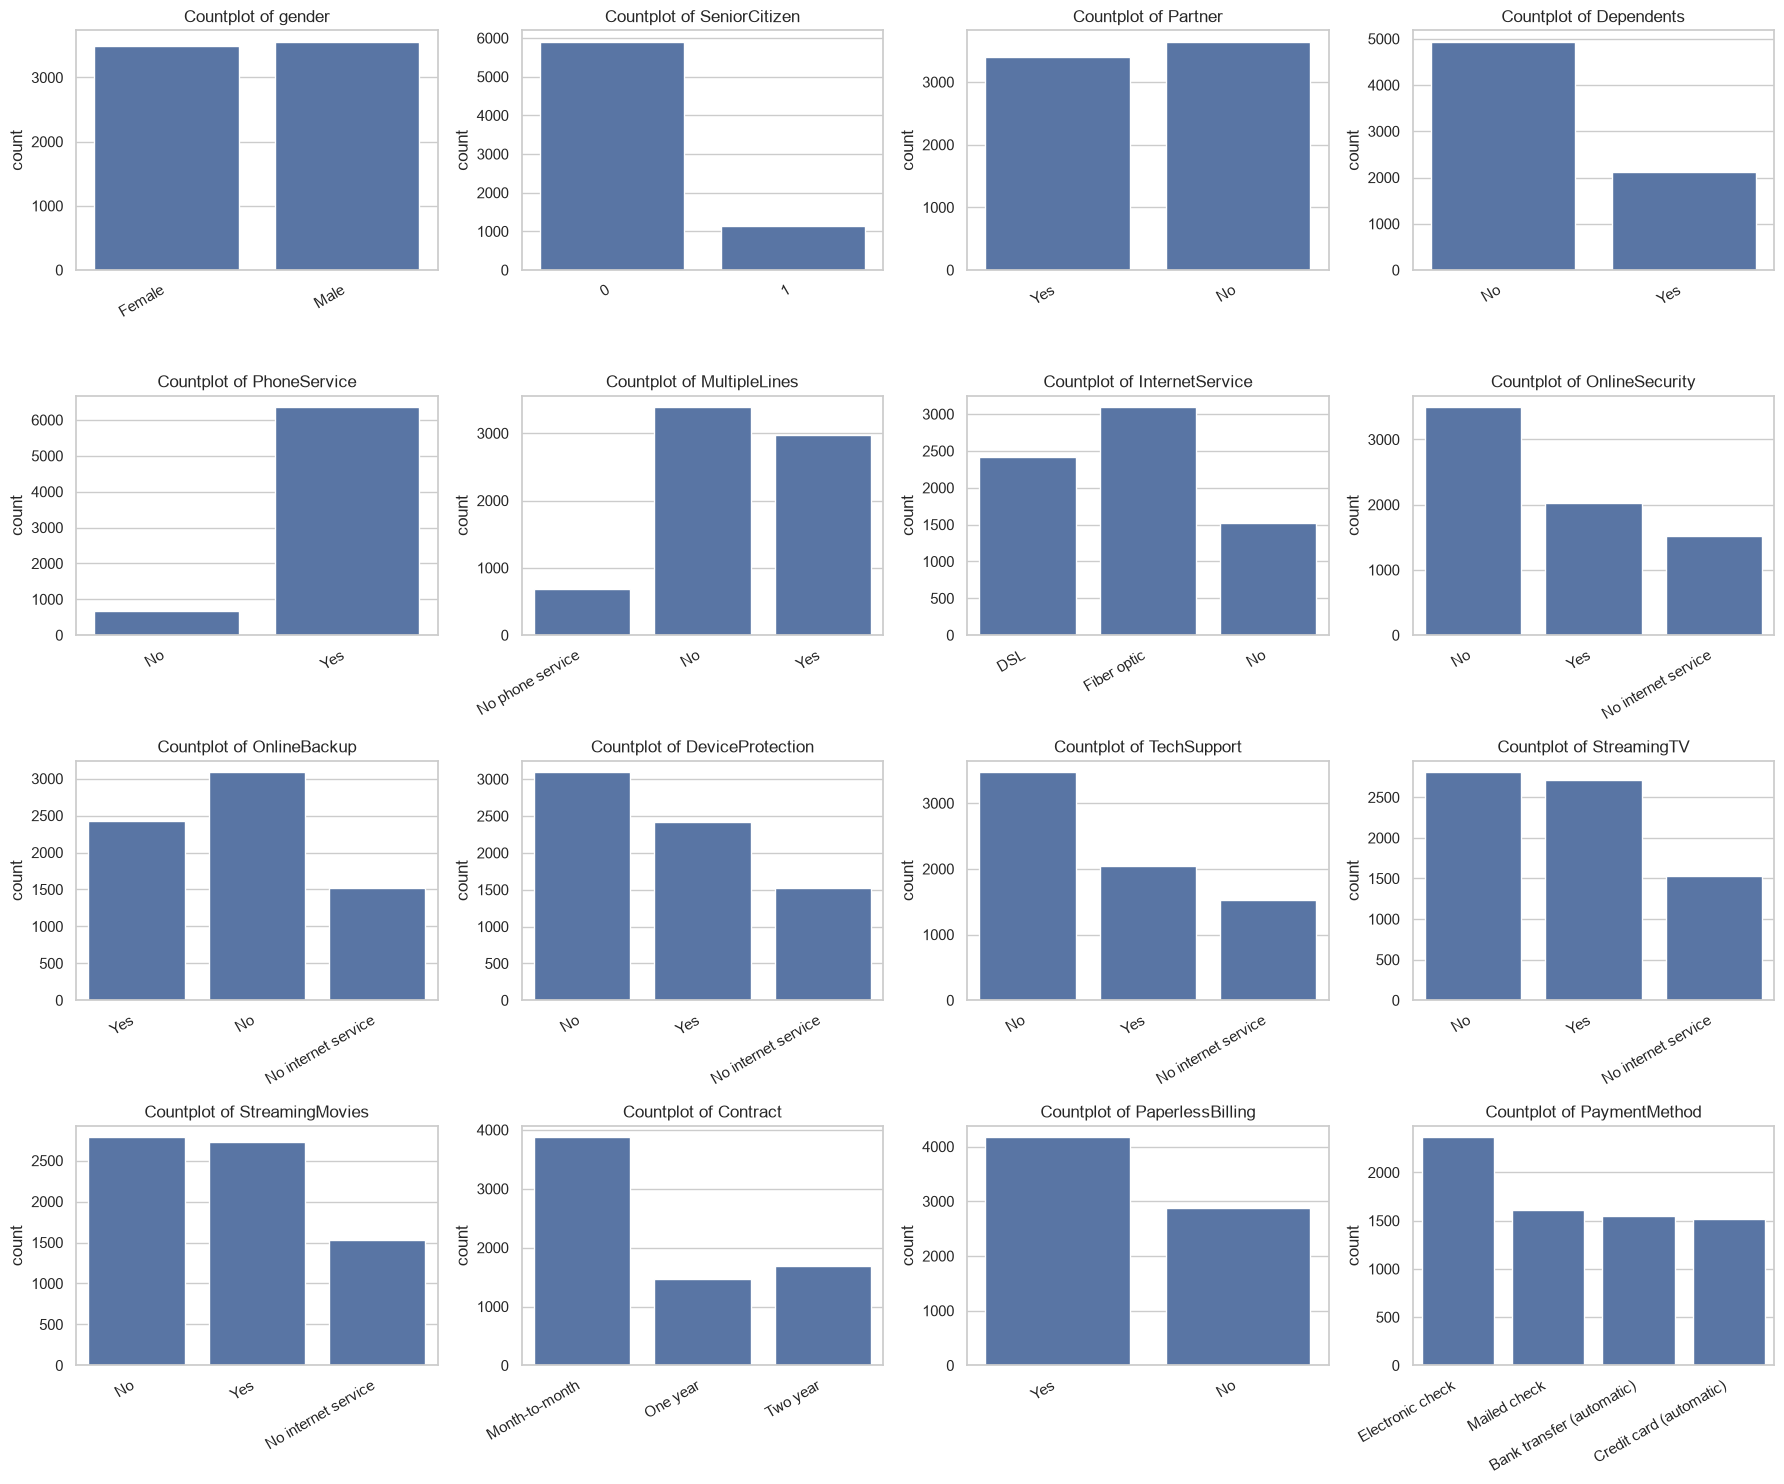

In [ ]:
cat_cols = [c for c in df.columns if c not in num_cols + ["Churn"]]   


fig, axes = plt.subplots(4, 4, figsize=(18,15))
for ax,col in zip(axes.flatten(),cat_cols):
    sns.countplot(x=df[col],ax=ax)
    ax.set_title(f"Countplot of {col}")
    ax.set_xlabel("")
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Ce que je vois :** 

                    *Variables très déséquilibrées :PhoneService : presque tous les clients ont le service téléphonique (très peu de « No »).   SeniorCitizen : très peu de personnes âgées (forte majorité de 0).   Dependents : une grande majorité de clients n'a pas de personnes à charge.   Contract : forte dominance des contrats mensuels (« Month-to-month ») par rapport aux contrats d'un ou deux ans.   *Variables avec la modalité « No phone service » :Uniquement MultipleLines (pour les clients sans ligne fixe).   Variables avec la modalité « No internet service » :Les 6 services additionnels liés à Internet : OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV et StreamingMovies. *

## 6. Le churn selon les variables

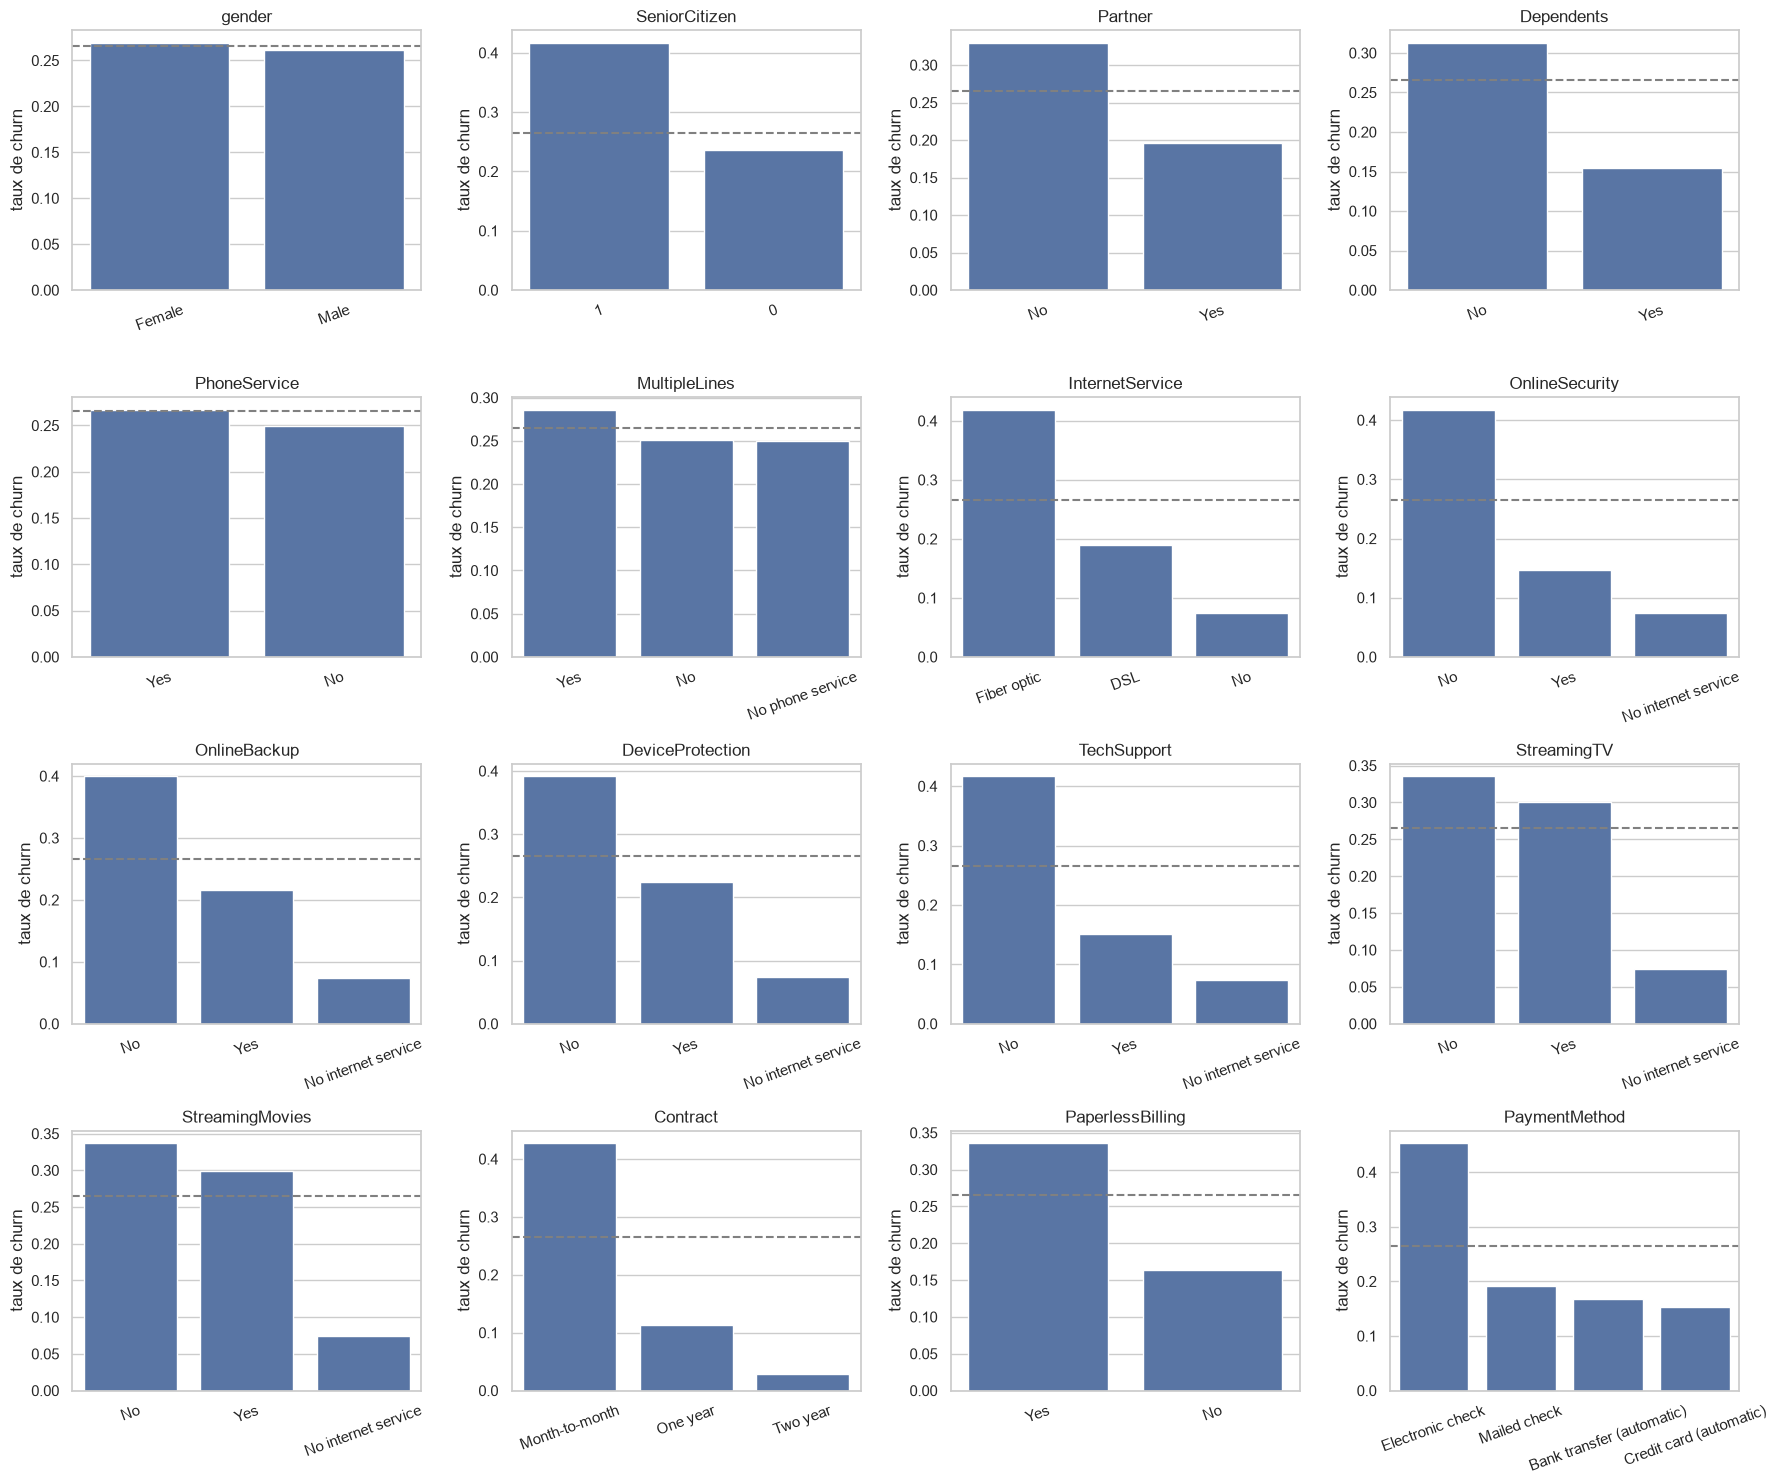

In [ ]:

fig, axes = plt.subplots(4, 4, figsize=(18, 15))

for ax, col in zip(axes.flatten(), cat_cols):
    taux = churn.groupby(df[col]).mean().sort_values(ascending=False)
    sns.barplot(x=taux.index.astype(str), y=taux.values, ax=ax)

    ax.axhline(churn.mean(), color="grey", linestyle="--")  
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("taux de churn")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### churn par contract

<Axes: xlabel='Contract', ylabel='count'>

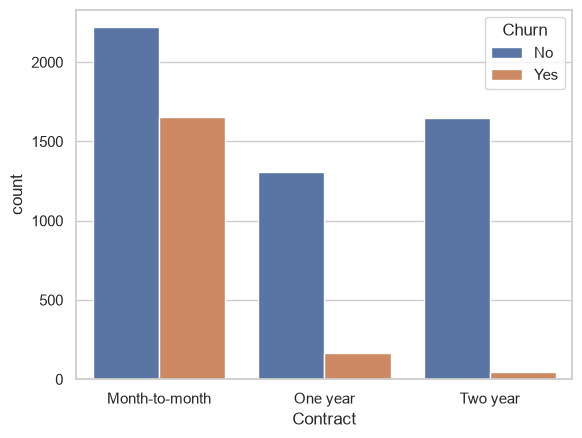

In [ ]:
sns.countplot(x=df["Contract"], hue=df["Churn"])

### Taux de churn par "Contract", "InternetService", "PaymentMethod", "TechSupport"

In [ ]:
for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport"]:
    print(churn.groupby(df[col]).mean().round(2).sort_values(ascending=False), "\n")

Contract
Month-to-month    0.43
One year          0.11
Two year          0.03
Name: Churn, dtype: float64 

InternetService
Fiber optic    0.42
DSL            0.19
No             0.07
Name: Churn, dtype: float64 

PaymentMethod
Electronic check             0.45
Mailed check                 0.19
Bank transfer (automatic)    0.17
Credit card (automatic)      0.15
Name: Churn, dtype: float64 

TechSupport
No                     0.42
Yes                    0.15
No internet service    0.07
Name: Churn, dtype: float64 



### Taux de churn selon l'ancienneté

tenure
0-12 mois    0.47
13-24        0.29
25-48        0.20
49-72        0.10
Name: Churn, dtype: float64


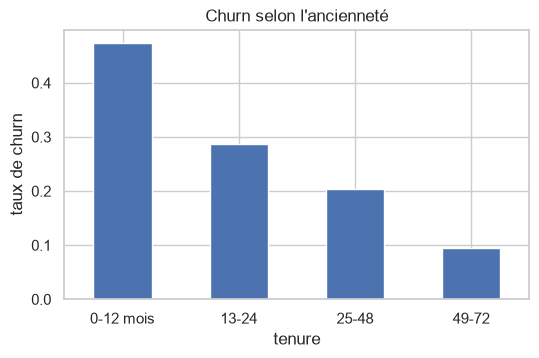

In [ ]:
tenure_group = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12 mois", "13-24", "25-48", "49-72"])
taux = churn.groupby(tenure_group, observed=True).mean()
print(taux.round(2))

taux.plot(kind="bar", rot=0, figsize=(6, 3.5), ylabel="taux de churn", title="Churn selon l'ancienneté")
plt.show()

**Ce que je vois :**
    
                 *Le risque d'attrition est le plus fort durant la première année (0-12 mois) avec un taux de 47 % ; plus l'ancienneté augmente, plus le risque diminue drastiquement (seulement 10 % au-delà de 4 ans).*

## 7. Constats et décisions pour la modélisation

**Constats (d'après les taux de churn calculés plus haut)**
- Contrat : 43 % de churn en mensuel, 11 % à un an, 3 % à deux ans.
- Internet : 42 % en fibre optique, 19 % en DSL, 7 % sans internet.
- Paiement : 45 % avec chèque électronique, contre 15 % à 19 % pour les autres modes.
- Support technique : 42 % sans support, 15 % avec.


**Décisions pour la suite**
- `TotalCharges` convertie en nombre, `customerID` supprimé.
- Cible `Churn` transformée en 0/1.
- Séparation train/test **stratifiée** pour garder environ 27 % de churn dans les deux parties.
- Déséquilibre des classes : `class_weight="balanced"` dans le modèle .
- Variables catégorielles : `OneHotEncoder` ; variables numériques : `StandardScaler`, le tout dans un `Pipeline`.
- `tenure` et `TotalCharges` sont liées : à surveiller.
- Métriques : recall et ROC-AUC, pas seulement l'accuracy.